## Practice Activity 7-1: Association Rules Mining

In the reading you analyzed transactions from a bakery. In this activity you will carry out a very similar analysis for purchases from a grocery store.

In [1]:
import pandas as pd

from plotnine import *

from mlxtend.frequent_patterns import apriori, association_rules

# to stop an annoying warning
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning, module="jupyter_client")

ModuleNotFoundError: No module named 'pandas'

## Groceries data set

- One month (30 days) of real point-of-sale transactions from a grocery store.
- 9,835 transactions (baskets).
- 169 product categories, such as whole milk, yogurt, bottled beer, etc.
- Source: the data set `Groceries` in the R package `arules`, provided by Hahsler, Hornik, and Reutterer. The copy we use is a plain-text version hosted on GitHub.


The file format is different from the bakery file. The bakery file had one row per item bought. This file has **one line per transaction**, and each line is a comma-separated list of the items in that basket. Different baskets have different numbers of items.

The next cell reads each line into a single text column. (Normal CSV reading expects every row to have the same number of columns, so we read each line as one string, using a separator `"|"` that never occurs in the file.)

In [ ]:
import csv

raw = pd.read_csv(
    "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/groceries.csv",
    header=None,             # the file has no header row: line 1 is already a transaction
    names=["basket"],        # name the one column we create
    sep="|",                 # "|" never appears in this file, so each whole line lands in one column
    quoting=csv.QUOTE_NONE,  # treat any quote characters as ordinary text
)

In [ ]:
raw

,basket
0,"citrus fruit,semi-finished bread,margarine,rea..."
1,"tropical fruit,yogurt,coffee"
2,whole milk
3,"pip fruit,yogurt,cream cheese ,meat spreads"
4,"other vegetables,whole milk,condensed milk,lon..."
...,...
9830,"sausage,chicken,beef,hamburger meat,citrus fru..."
9831,cooking chocolate
9832,"chicken,citrus fruit,other vegetables,butter,y..."
9833,"semi-finished bread,bottled water,soda,bottled..."


We'll start with the data in long format like in the reading.

- Make a column `basket_id` from the row number (`raw.index`).
- Split the text in `raw["basket"]` at the commas, using `.str.split(",")`. This produces a *list* of items in each row.
- Use `.explode(...)` on the column of lists to get one row per item.
- Keep only `basket_id` and `item`, and use `.reset_index(drop=True)`.
- Trim spaces

In [ ]:
long = (
    raw
    .assign(basket_id=raw.index)                    # use the row number as the basket ID
    .assign(item=raw["basket"].str.split(","))      # "milk,bread" becomes ["milk", "bread"]
    .explode("item")                                # one row per (basket, item)
    [["basket_id", "item"]]                         # keep only the two columns we need
    .reset_index(drop=True)                         # renumber the rows 0, 1, 2, ...
)

long["item"] = long["item"].str.strip()             # remove stray leading/trailing spaces

long

,basket_id,item
0,0,citrus fruit
1,0,semi-finished bread
2,0,margarine
3,0,ready soups
4,1,tropical fruit
...,...,...
43362,9834,chicken
43363,9834,tropical fruit
43364,9834,other vegetables
43365,9834,vinegar


1. Build the transaction-by-item table `basket`. There should be one row per basket, one column per item, with `True` if the item is in the basket and `False` otherwise.

In [ ]:
basket = (
    long
    .drop_duplicates()                      # an item counted once per basket
    .assign(indicator=True)
    .pivot(index="basket_id", columns="item", values="indicator")
    .fillna(False)
    .astype(bool)
)
basket

/tmp/ipykernel_5315/2714485423.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


item,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
basket_id,,,,,,,,,,,,,,,,,,,,,
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9830,False,False,False,False,False,False,False,False,False,True,...,False,False,False,True,False,False,False,True,False,False
9831,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9832,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False


2.  Compute the size (number of items) of each basket and store it in `basket_sizes`.

In [ ]:
basket_sizes = basket.sum(axis=1)
basket_sizes

,0
basket_id,
0,4
1,3
2,1
3,4
4,4
...,...
9830,17
9831,1
9832,10


3. Summarize the distribution of the number of items.

count    9835.000000
mean        4.409456
std         3.589385
min         1.000000
25%         2.000000
50%         3.000000
75%         6.000000
max        32.000000
dtype: float64


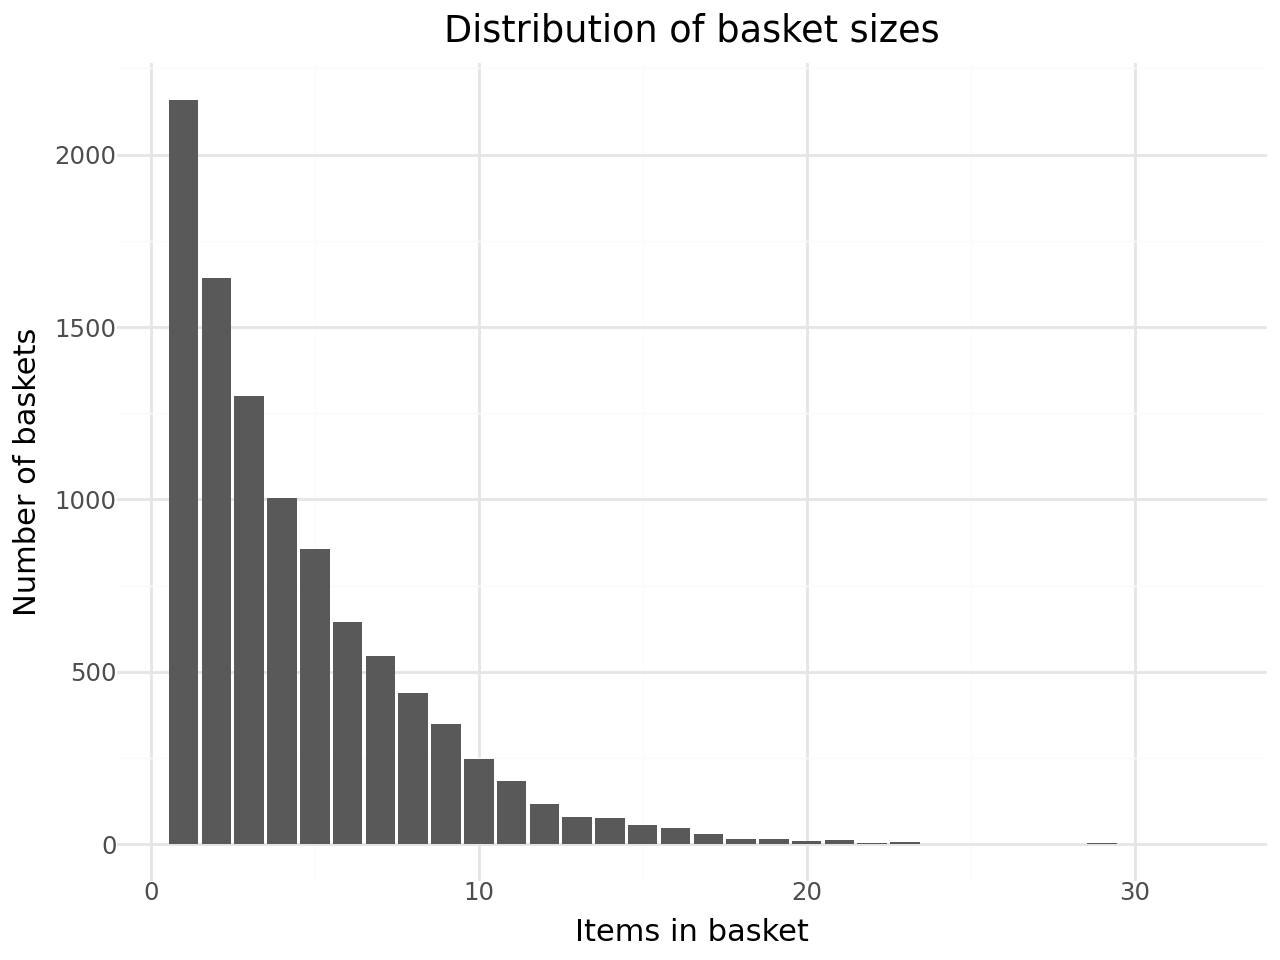

In [ ]:
print(basket_sizes.describe())

sizes_df = basket_sizes.value_counts().sort_index().rename_axis("n_items").reset_index(name="n_baskets")

(
    ggplot(sizes_df, aes(x="n_items", y="n_baskets"))
    + geom_col()
    + labs(x="Items in basket", y="Number of baskets", title="Distribution of basket sizes")
    + theme_minimal()
)

4. Compute the support of every item, sorted from largest to smallest, and store it in `item_support`. Then make a horizontal bar chart of the 15 most popular items.

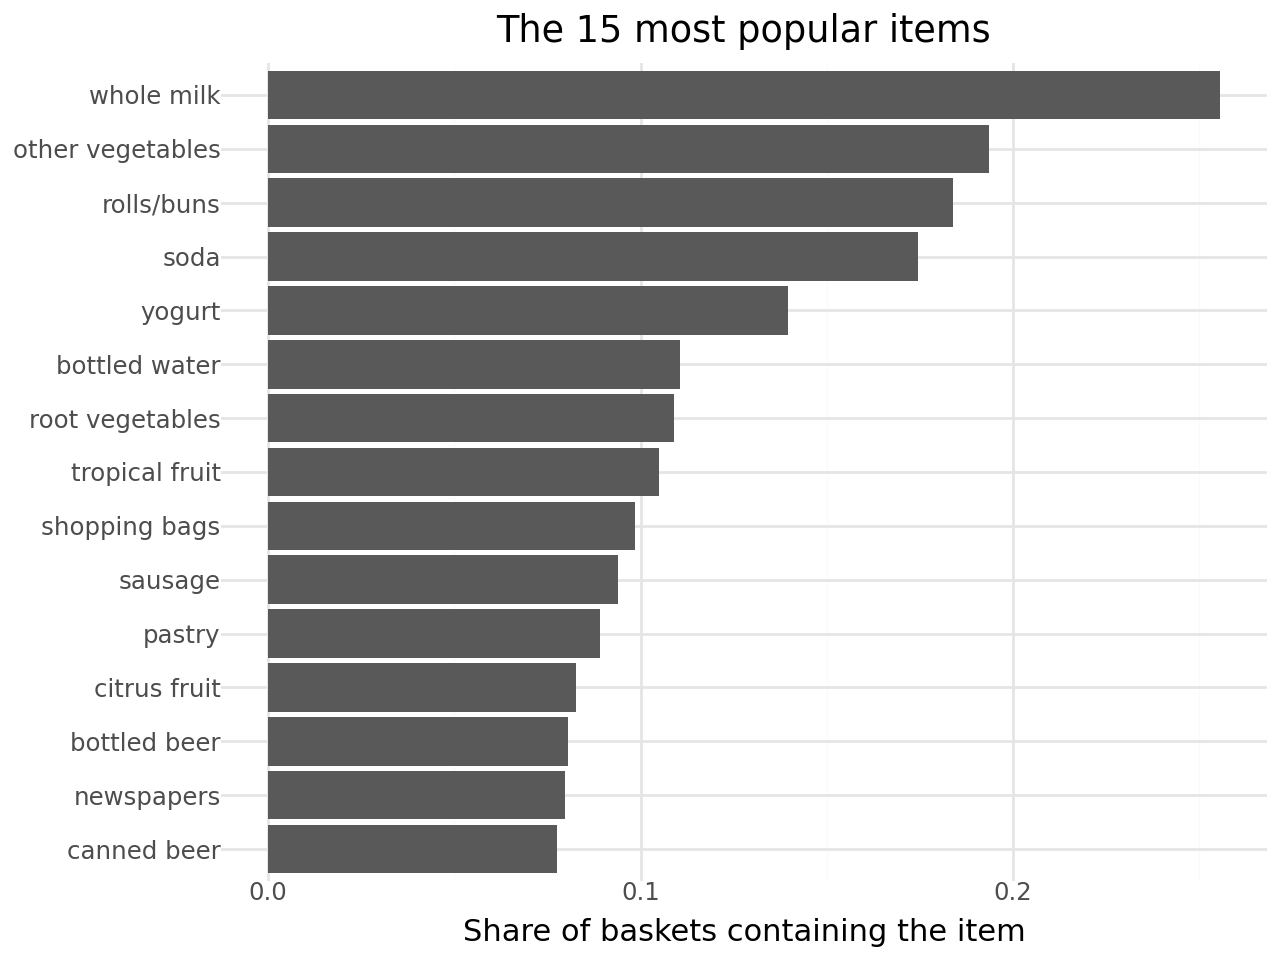

In [ ]:
item_support = basket.mean().sort_values(ascending=False)

top15 = item_support.head(15).rename("support").reset_index()
top15["item"] = pd.Categorical(top15["item"], categories=top15["item"].tolist()[::-1], ordered=True)

(
    ggplot(top15, aes(x="item", y="support"))
    + geom_col()
    + coord_flip()
    + labs(x="", y="Share of baskets containing the item", title="The 15 most popular items")
    + theme_minimal()
)

5. Consider the basket sizes and the item supports. Which item is most popular, and in what percentage of baskets does it appear? Which items are most common? What does this suggest about the "popular items co-occur just by chance" problem discussed in the reading?

Baskets are bigger than at the bakery, the median has 3 items but distribution is right skewed. About 22% of baskets have one item. Milk appears in 25.6% of baskets which makes sense because milk is a very important item. Other commmon items are vegetables, rolls / buns, soda, and yogurt.

6. Consider the rule **{yogurt} → {whole milk}**. Compute and interpret the confidence of this rule.


In [ ]:
yogurt_support = basket["yogurt"].mean()
milk_support = basket["whole milk"].mean()
yogurt_milk_support = (basket["yogurt"] & basket["whole milk"]).mean()

yogurt_to_milk_conf = yogurt_milk_support / yogurt_support
yogurt_to_milk_conf

np.float64(0.40160349854227406)

7. Compute and interpret the **lift** of {yogurt} → {whole milk}.

In [ ]:
yogurt_to_milk_lift = yogurt_to_milk_conf / milk_support
yogurt_to_milk_lift

np.float64(1.5717351405345266)

8. Now compute and interpret the confidence and lift for the rule {whole milk} → {yogurt}.

In [ ]:
milk_to_yogurt_conf = yogurt_milk_support / milk_support
milk_to_yogurt_lift = milk_to_yogurt_conf / yogurt_support
milk_to_yogurt_conf, milk_to_yogurt_lift

(np.float64(0.21925984878631116), np.float64(1.5717351405345263))

9. Write two functions.

- `support(items, onehot)`: returns the share of baskets that contain **all** of the items in the list `items`.
- `rule_metrics(antecedent, consequent, onehot)`: returns a Pandas Series with the `support`, `confidence`, and `lift` of the rule `antecedent -> consequent`. Both `antecedent` and `consequent` are *lists* of items.

Test the functions on `["yogurt"]` → `["whole milk"]`. The values should match the ones you computed earlier.

In [ ]:
def support(items, onehot):
    '''Share of baskets that contain ALL of the given items.'''
    return onehot[list(items)].all(axis=1).mean()

def rule_metrics(antecedent, consequent, onehot):
    '''Support, confidence, and lift of antecedent -> consequent.'''
    a = list(antecedent)
    c = list(consequent)
    s_a = support(a, onehot)
    s_c = support(c, onehot)
    s_ac = support(a + c, onehot)
    return pd.Series({
        "support": s_ac,
        "confidence": s_ac / s_a,
        "lift": s_ac / (s_a * s_c),
    })

rule_metrics(["yogurt"], ["whole milk"], basket)

,0
support,0.056024
confidence,0.401603
lift,1.571735


10. Whole milk is in about a quarter of all baskets. Consider the rules `{X} → {whole milk}` for the five antecedents `X` in the next cell. Before running anything, predict: for which of these will the lift be **above 1**? For which might the confidence look decent but the lift be **close to or below 1**? Just think about this before proceeding.

In [ ]:
antecedents = pd.Series(["yogurt", "rolls/buns", "bottled water", "soda", "other vegetables"])

11. Compute the support, confidence, and lift of `{X} → {whole milk}` for each of the five antecedents above, and display the results sorted by lift (largest first). Compare to your predictions. Hint: Use `apply` with `lambda` on the Series of antecedents.


In [ ]:
milk_rules = antecedents.apply(lambda x: rule_metrics([x], ["whole milk"], basket))
milk_rules.index = antecedents + " -> whole milk"
milk_rules.sort_values("lift", ascending=False)

,support,confidence,lift
yogurt -> whole milk,0.056024,0.401603,1.571735
other vegetables -> whole milk,0.074835,0.386758,1.513634
bottled water -> whole milk,0.034367,0.310948,1.216940
rolls/buns -> whole milk,0.056634,0.307905,1.205032
soda -> whole milk,0.040061,0.229738,0.899112


12. Run `apriori` on `basket` with `min_support=0.01` and store the result in `frequent_itemsets`. Then add a column `n_items` giving the number of items in each itemset.

In [ ]:
frequent_itemsets = apriori(basket, min_support=0.01, use_colnames=True)
frequent_itemsets["n_items"] = frequent_itemsets["itemsets"].apply(len)

# only if make_rules isn't already defined in your notebook
def make_rules(itemsets, min_confidence):
    return association_rules(itemsets, num_itemsets=len(basket),
                             metric="confidence", min_threshold=min_confidence)

frequent_itemsets["n_items"].value_counts().sort_index()

,count
n_items,
1,88
2,213
3,32


13. Generate the rules with `make_rules`, keeping rules with confidence of at least 0.20. Store them in `rules` and print how many there are.

In [ ]:
rules = make_rules(frequent_itemsets, 0.20)
print(len(rules))

234


14. Make the rules easier to read. Create a copy `rules_display` of `rules` and add three columns:

- `antecedent`: the antecedent items as text, e.g. `"tropical fruit, yogurt"`
- `consequent`: the consequent items as text
- `transactions`: the number of baskets that contain the whole rule (support times the number of baskets, rounded to an integer)

Then display the columns `antecedent`, `consequent`, `support`, `confidence`, `lift`, `transactions` for the first 8 rules.

In [ ]:
rules_display = rules.copy()
rules_display["antecedent"] = rules_display["antecedents"].apply(lambda x: ", ".join(sorted(x)))
rules_display["consequent"] = rules_display["consequents"].apply(lambda x: ", ".join(sorted(x)))
rules_display["transactions"] = (rules_display["support"] * len(basket)).round().astype(int)

cols = ["antecedent", "consequent", "support", "confidence", "lift", "transactions"]
rules_display[cols].head(8)

,antecedent,consequent,support,confidence,lift,transactions
0,beef,other vegetables,0.019725,0.375969,1.943066,194
1,beef,rolls/buns,0.013625,0.259690,1.411858,134
2,beef,root vegetables,0.017387,0.331395,3.040367,171
3,beef,whole milk,0.021251,0.405039,1.585180,209
4,beef,yogurt,0.011693,0.222868,1.597601,115
5,berries,other vegetables,0.010269,0.308869,1.596280,101
6,berries,whole milk,0.011795,0.354740,1.388328,116
7,berries,yogurt,0.010574,0.318043,2.279848,104


15. Show the 10 rules with the highest **confidence**. What do the highest-confidence rules have in common? Why is confidence alone a poor guide here?

In [ ]:
rules_display.sort_values("confidence", ascending=False)[cols].head(10)

,antecedent,consequent,support,confidence,lift,transactions
157,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608,102
186,"root vegetables, tropical fruit",other vegetables,0.012303,0.584541,3.020999,121
163,"curd, yogurt",whole milk,0.010066,0.582353,2.279125,99
153,"butter, other vegetables",whole milk,0.011490,0.573604,2.244885,113
222,"root vegetables, tropical fruit",whole milk,0.011998,0.570048,2.230969,118
224,"root vegetables, yogurt",whole milk,0.014540,0.562992,2.203354,143
165,"domestic eggs, other vegetables",whole milk,0.012303,0.552511,2.162336,121
232,"whipped/sour cream, yogurt",whole milk,0.010880,0.524510,2.052747,107
213,"rolls/buns, root vegetables",whole milk,0.012710,0.523013,2.046888,125
171,"other vegetables, pip fruit",whole milk,0.013523,0.517510,2.025351,133


16. Show the 10 rules with the highest **lift**. Compare this list with the highest-confidence list. What kinds of products appear now? Look at the `support` and `transactions` columns: how much evidence is each of these rules based on?

In [ ]:
rules_display.sort_values("lift", ascending=False)[cols].head(10)

,antecedent,consequent,support,confidence,lift,transactions
156,"citrus fruit, other vegetables",root vegetables,0.010371,0.359155,3.295045,102
207,"other vegetables, yogurt",whipped/sour cream,0.010168,0.234192,3.267062,100
185,"other vegetables, tropical fruit",root vegetables,0.012303,0.342776,3.144780,121
2,beef,root vegetables,0.017387,0.331395,3.040367,171
157,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608,102
186,"root vegetables, tropical fruit",other vegetables,0.012303,0.584541,3.020999,121
188,"other vegetables, whole milk",root vegetables,0.023183,0.309783,2.842082,228
190,root vegetables,"other vegetables, whole milk",0.023183,0.212687,2.842082,228
155,butter,"other vegetables, whole milk",0.011490,0.207339,2.770630,113
164,"curd, whole milk",yogurt,0.010066,0.385214,2.761356,99


17. Create `interesting_rules`: the rules with **confidence of at least 0.30 and lift of at least 1.5**, sorted by lift (largest first).


In [ ]:
interesting_rules = (
    rules_display[(rules_display["confidence"] >= 0.30) & (rules_display["lift"] >= 1.5)]
    .sort_values("lift", ascending=False)
)
interesting_rules[cols]

,antecedent,consequent,support,confidence,lift,transactions
156,"citrus fruit, other vegetables",root vegetables,0.010371,0.359155,3.295045,102
185,"other vegetables, tropical fruit",root vegetables,0.012303,0.342776,3.144780,121
2,beef,root vegetables,0.017387,0.331395,3.040367,171
157,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608,102
186,"root vegetables, tropical fruit",other vegetables,0.012303,0.584541,3.020999,121
...,...,...,...,...,...,...
89,onions,whole milk,0.012100,0.390164,1.526965,119
72,hygiene articles,whole milk,0.012811,0.388889,1.521975,126
17,brown bread,whole milk,0.025216,0.388715,1.521293,248
105,other vegetables,whole milk,0.074835,0.386758,1.513634,736


18. Choose **one** rule from the table and interpret its **support**, **confidence**, and **lift** with numbers, as you did for {yogurt} → {whole milk}.

citrus, fruit, other vegetables --> root vegetables

Support: 1% of all baskets contain all 3 items
confidence: of baskets with citrus and other vegetables, 35.9% also have root vegetabels
lift: root vegetables appear in 10.9% of baskets overall, so they are 3.3 times as likely in citrus-vegetable baskets


19. The manager wants to **increase sales of yogurt**. Which products should the store link to yogurt (shelf placement, a joint promotion, a recommendation)?

Based on following code it seems like the store manager should link dairy products with yogurt. Milk, whipped cream, sour cream, and even fruit have the highest confidence. This makes sense as dairy products are all in the same family, and fruit is freqeuntly eaten with yogurt.

In [ ]:
all_rules = make_rules(frequent_itemsets, 0)

to_yogurt = all_rules[all_rules["consequents"] == frozenset({"yogurt"})]
to_yogurt["transactions"] = (to_yogurt["support"] * len(basket)).round().astype(int)
to_yogurt[["antecedents", "support", "confidence", "lift", "transactions"]].sort_values("lift", ascending=False).head(15)

/tmp/ipykernel_5315/3969127201.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


,antecedents,support,confidence,lift,transactions
457,"(curd, whole milk)",0.010066,0.385214,2.761356,99
608,"(whole milk, tropical fruit)",0.015150,0.358173,2.567516,149
560,"(other vegetables, whipped/sour cream)",0.010168,0.352113,2.524073,100
548,"(other vegetables, tropical fruit)",0.012303,0.342776,2.457146,121
614,"(whipped/sour cream, whole milk)",0.010880,0.337539,2.419607,107
452,"(citrus fruit, whole milk)",0.010269,0.336667,2.413350,101
154,(curd),0.017285,0.324427,2.325615,170
15,(berries),0.010574,0.318043,2.279848,104
140,(cream cheese),0.012405,0.312821,2.242412,122
566,"(other vegetables, whole milk)",0.022267,0.297554,2.132979,219


---
## References and attribution


- Hahsler, M., Gr&uuml;n, B., and Hornik, K. (2005). arules: A computational environment for mining association rules and frequent item sets. *Journal of Statistical Software*, 14(15). (The R package that distributes the data.)
- Data copy: GitHub repository `stedy/Machine-Learning-with-R-datasets` (`groceries.csv`), the data used in Lantz, B., *Machine Learning with R*.
- Raschka, S. (2018). MLxtend: Providing machine learning and data science utilities and extensions to Python's scientific computing stack. *Journal of Open Source Software*, 3(24), 638. <https://doi.org/10.21105/joss.00638>


**Preparation of this notebook:** drafted with the assistance of generative AI tools (ChatGPT and Claude).